In [1]:
import numpy as np, pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from noharm_fl.certify.bounds import clip_loss, eb_pvalue, betting_pvalue, fixed_sequence

df = pd.read_parquet("../data/interim/sparcs_2022_adults.parquet").reset_index(drop=True)
df["split"] = pd.read_parquet("../data/splits/split_seed0.parquet")["split"].values   # PILOT seed
df["dx_sys"] = df["ccsr_diagnosis_code"].str[:3]
cols = ["age_group", "gender", "race", "ethnicity", "type_of_admission",
        "emergency_department_indicator", "payment_typology_1", "dx_sys"]
X = OneHotEncoder(handle_unknown="ignore", min_frequency=50).fit_transform(df[cols].fillna("NA")).tocsr()
y = df["y"].values; h = df["permanent_facility_id"].values
tr = (df["split"] == "train").values; ce = (df["split"] == "cert").values
keep = df.groupby("permanent_facility_id")["y"].sum().loc[lambda s: s >= 100].index
fed = LogisticRegression(C=1.0, max_iter=300).fit(X[tr], y[tr])

B, alpha = 5.0, 0.05
blends = [0.25, 0.5, 0.75, 1.0]
eps_grid = [0.001, 0.005, 0.01, 0.02]
D = {}
for k in keep:
    mk = (h == k); a_, b_ = mk & tr, mk & ce
    loc = LogisticRegression(C=1.0, max_iter=300).fit(X[a_], y[a_])
    pl = loc.predict_proba(X[b_])[:, 1]; pf = fed.predict_proba(X[b_])[:, 1]
    l0 = clip_loss(pl, y[b_], B)
    D[k] = [clip_loss((1 - a) * pl + a * pf, y[b_], B) - l0 for a in blends]

rows = []
for eps in eps_grid:
    for name, fn in [("empirical-Bernstein", eb_pvalue), ("betting", betting_pvalue)]:
        sel = [fixed_sequence([fn(d, eps, -B, B, alpha) for d in D[k]], alpha) for k in keep]
        sel = np.array(sel)
        rows.append((eps, name, int((sel >= 0).sum()), len(keep), round(float(np.mean([blends[s] if s >= 0 else 0 for s in sel])), 3)))
print(pd.DataFrame(rows, columns=["eps", "bound", "hospitals_with_nonlocal", "of", "mean_blend"]))

     eps                bound  hospitals_with_nonlocal   of  mean_blend
0  0.001  empirical-Bernstein                        0  126       0.000
1  0.001              betting                        0  126       0.000
2  0.005  empirical-Bernstein                        0  126       0.000
3  0.005              betting                       17  126       0.083
4  0.010  empirical-Bernstein                        3  126       0.012
5  0.010              betting                       57  126       0.373
6  0.020  empirical-Bernstein                       31  126       0.183
7  0.020              betting                       99  126       0.750


In [1]:
import numpy as np, pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

res = pd.read_csv("../outputs/tables/harm_seed100_noapr.csv")

def harm_count(diff, se, eps):
    diff, se = np.asarray(diff, float), np.asarray(se, float)
    z = np.where(se > 0, (diff - eps) / np.where(se > 0, se, 1), -np.inf)
    p = 1 - stats.norm.cdf(z)
    return int(multipletests(p, alpha=0.05, method="holm")[0].sum())

rows = []
for eps in [0.005, 0.01, 0.02]:
    rows.append({
        "eps": eps,
        "certified_harmed(>eps)": harm_count(res[f"seldiff_eps{eps}"], res[f"selse_eps{eps}"], eps),
        "certified_worst_regret": res[f"seldiff_eps{eps}"].max(),
        "pooled_harmed(>eps)": harm_count(res["diff_b1.0"], res["se_b1.0"], eps),
        "pooled_worst_regret": res["diff_b1.0"].max(),
        "blend0.75_harmed(>eps)": harm_count(res["diff_b0.75"], res["se_b0.75"], eps),
    })
print(pd.DataFrame(rows).round(4))

     eps  certified_harmed(>eps)  certified_worst_regret  pooled_harmed(>eps)  \
0  0.005                       0                  0.0010                    1   
1  0.010                       0                  0.0047                    0   
2  0.020                       0                  0.0131                    0   

   pooled_worst_regret  blend0.75_harmed(>eps)  
0               0.0246                       1  
1               0.0246                       0  
2               0.0246                       0  


In [2]:
rows = []
for eps in [0.005, 0.01, 0.02]:
    rows.append({"eps": eps,
        "pooled_raw_share_above_eps": (res["diff_b1.0"] > eps).mean(),
        "blend0.75_raw_share_above_eps": (res["diff_b0.75"] > eps).mean(),
        "certified_raw_share_above_eps": (res[f"seldiff_eps{eps}"] > eps).mean(),
        "pooled_hospitals_above_eps": int((res["diff_b1.0"] > eps).sum()),
        "certified_hospitals_above_eps": int((res[f"seldiff_eps{eps}"] > eps).sum())})
print(pd.DataFrame(rows).round(4))
print(res.assign(big=res["diff_b1.0"] > 0.005).groupby("big")[["n_train", "deaths_train"]].median())

     eps  pooled_raw_share_above_eps  blend0.75_raw_share_above_eps  \
0  0.005                      0.2540                         0.0873   
1  0.010                      0.0952                         0.0317   
2  0.020                      0.0238                         0.0000   

   certified_raw_share_above_eps  pooled_hospitals_above_eps  \
0                            0.0                          32   
1                            0.0                          12   
2                            0.0                           3   

   certified_hospitals_above_eps  
0                              0  
1                              0  
2                              0  
       n_train  deaths_train
big                         
False   5058.0         169.5
True    5846.5         179.0


In [3]:
import numpy as np, pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests

def hc(diff, se, eps):
    diff, se = np.asarray(diff, float), np.asarray(se, float)
    z = np.where(se > 0, (diff - eps) / np.where(se > 0, se, 1), -np.inf)
    return int(multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0].sum())

seeds = [101, 102, 103, 104]
R = {s: pd.read_csv(f"../outputs/tables/harm_seed{s}_noapr.csv") for s in seeds}

rows = []
for eps in [0.0, 0.005, 0.01, 0.02]:
    for name, dc, sc in [("pooled", "diff_b1.0", "se_b1.0"), ("blend 0.75", "diff_b0.75", "se_b0.75")]:
        c = [hc(R[s][dc], R[s][sc], eps) for s in seeds]
        rows.append((eps, name, np.mean(c), min(c), max(c), np.mean([(R[s][dc] > eps).mean() for s in seeds]), np.mean([R[s][dc].max() for s in seeds])))
    if eps > 0:
        c = [hc(R[s][f"seldiff_eps{eps}"], R[s][f"selse_eps{eps}"], eps) for s in seeds]
        rows.append((eps, "certified", np.mean(c), min(c), max(c), np.mean([(R[s][f"seldiff_eps{eps}"] > eps).mean() for s in seeds]), np.mean([R[s][f"seldiff_eps{eps}"].max() for s in seeds])))
print(pd.DataFrame(rows, columns=["eps", "method", "mean_harmed", "min", "max", "raw_share", "mean_worst_regret"]).round(4))

big = pd.concat([R[s].assign(seed=s) for s in seeds])
big["size_q"] = pd.qcut(big["n_train"], 4, labels=["smallest", "q2", "q3", "largest"])
print(big.groupby("size_q", observed=True).agg(hospitals=("hospital", "nunique"), pooled_mean_diff=("diff_b1.0", "mean"),
      pooled_raw_worse=("diff_b1.0", lambda s: (s > 0).mean()),
      certified_nonlocal_eps01=("sel_eps0.01", lambda s: (s > 0).mean())).round(4))

      eps      method  mean_harmed  min  max  raw_share  mean_worst_regret
0   0.000      pooled        16.25   13   20     0.6885             0.0221
1   0.000  blend 0.75         7.25    5    9     0.5893             0.0124
2   0.005      pooled         1.25    0    3     0.2560             0.0221
3   0.005  blend 0.75         0.25    0    1     0.0675             0.0124
4   0.005   certified         0.00    0    0     0.0000             0.0022
5   0.010      pooled         0.00    0    0     0.0774             0.0221
6   0.010  blend 0.75         0.00    0    0     0.0139             0.0124
7   0.010   certified         0.00    0    0     0.0000             0.0051
8   0.020      pooled         0.00    0    0     0.0159             0.0221
9   0.020  blend 0.75         0.00    0    0     0.0000             0.0124
10  0.020   certified         0.00    0    0     0.0000             0.0126
          hospitals  pooled_mean_diff  pooled_raw_worse  \
size_q                                   

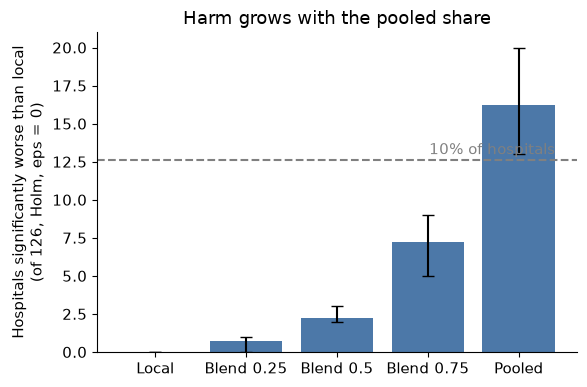

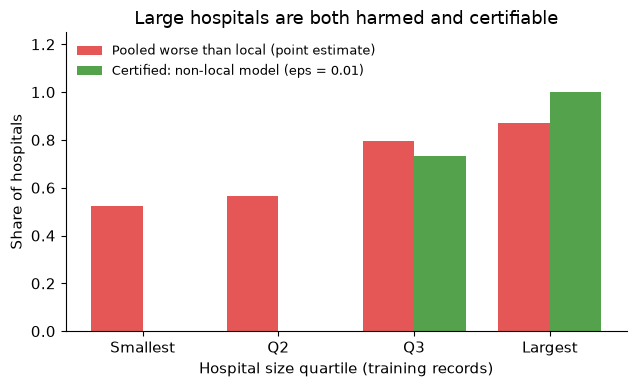

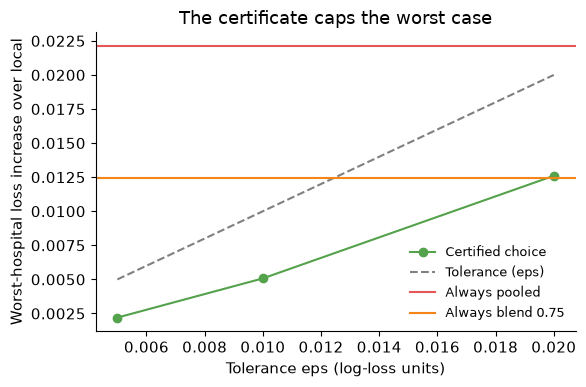

In [4]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
import os
os.makedirs("../outputs/figures", exist_ok=True)
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})

seeds = [101, 102, 103, 104]
R = {s: pd.read_csv(f"../outputs/tables/harm_seed{s}_noapr.csv") for s in seeds}
def hc(diff, se, eps):
    diff, se = np.asarray(diff, float), np.asarray(se, float)
    z = np.where(se > 0, (diff - eps) / np.where(se > 0, se, 1), -np.inf)
    return int(multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0].sum())
def save(name):
    plt.tight_layout(); plt.savefig(f"../outputs/figures/{name}.png", dpi=300); plt.savefig(f"../outputs/figures/{name}.pdf"); plt.show()

# Figure 1: hospitals significantly harmed (eps = 0) by how federated the model is
labs = ["Local", "Blend 0.25", "Blend 0.5", "Blend 0.75", "Pooled"]
cols = [None, "b0.25", "b0.5", "b0.75", "b1.0"]
m, lo, hi = [0], [0], [0]
for c in cols[1:]:
    v = [hc(R[s][f"diff_{c}"], R[s][f"se_{c}"], 0.0) for s in seeds]
    m.append(np.mean(v)); lo.append(np.mean(v) - min(v)); hi.append(max(v) - np.mean(v))
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(labs, m, yerr=[lo, hi], capsize=4, color="#4C78A8")
ax.axhline(0.10 * 126, ls="--", c="grey"); ax.text(4.4, 0.10 * 126 + 0.4, "10% of hospitals", ha="right", color="grey")
ax.set_ylabel("Hospitals significantly worse than local\n(of 126, Holm, eps = 0)"); ax.set_title("Harm grows with the pooled share")
save("fig1_harm_by_candidate")

# Figure 2: who is protected, by hospital size quartile
big = pd.concat([R[s].assign(seed=s) for s in seeds])
big["size_q"] = pd.qcut(big["n_train"], 4, labels=["Smallest", "Q2", "Q3", "Largest"])
g = big.groupby("size_q", observed=True)
x = np.arange(4); w = 0.38
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(x - w / 2, g["diff_b1.0"].apply(lambda s: (s > 0).mean()), w, label="Pooled worse than local (point estimate)", color="#E45756")
ax.bar(x + w / 2, g["sel_eps0.01"].apply(lambda s: (s > 0).mean()), w, label="Certified: non-local model (eps = 0.01)", color="#54A24B")
ax.set_xticks(x); ax.set_xticklabels(["Smallest", "Q2", "Q3", "Largest"]); ax.set_xlabel("Hospital size quartile (training records)")
ax.set_ylabel("Share of hospitals"); ax.legend(frameon=False, fontsize=9, loc="upper left"); ax.set_ylim(0, 1.25)
ax.set_title("Large hospitals are both harmed and certifiable")
save("fig2_size_quartiles")

# Figure 3: price of no-harm, worst-hospital regret against the tolerance
eps_list = [0.005, 0.01, 0.02]
cert = [np.mean([R[s][f"seldiff_eps{e}"].max() for s in seeds]) for e in eps_list]
pool = np.mean([R[s]["diff_b1.0"].max() for s in seeds]); b75 = np.mean([R[s]["diff_b0.75"].max() for s in seeds])
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(eps_list, cert, "o-", c="#54A24B", label="Certified choice")
ax.plot(eps_list, eps_list, "--", c="grey", label="Tolerance (eps)")
ax.axhline(pool, c="#E45756", label="Always pooled"); ax.axhline(b75, c="#F58518", label="Always blend 0.75")
ax.set_xlabel("Tolerance eps (log-loss units)"); ax.set_ylabel("Worst-hospital loss increase over local")
ax.legend(frameon=False, fontsize=9); ax.set_title("The certificate caps the worst case")
save("fig3_worst_regret")

In [5]:
import numpy as np, pandas as pd
from scipy import stats
from sklearn.linear_model import LogisticRegression
from noharm_fl.data.features import load
from noharm_fl.certify.bounds import calibration_gap_bound, calibration_gap_bound_clipped, worst_case_cal_gap

df = pd.read_parquet("../data/interim/sparcs_2022_adults.parquet").reset_index(drop=True)
X, y, h, split, keep = load(0)
tr, ce = split == "train", split == "cert"
pooled = LogisticRegression(C=1.0, max_iter=300).fit(X[tr], y[tr])
groups = ["gender", "age_band", "race_grp"]
deltas = [0.005, 0.01, 0.02, 0.03]
z = stats.norm.ppf(1 - 0.05 / 4)

def normal_gap(p_m, p_0, yy):
    e0 = p_0 - yy; dd = p_m - p_0
    m0, s0 = e0.mean(), e0.std(ddof=1) / np.sqrt(len(e0)); mb, sb = dd.mean(), dd.std(ddof=1) / np.sqrt(len(dd))
    return worst_case_cal_gap(m0 - z * s0, m0 + z * s0, mb - z * sb, mb + z * sb)

rows = []
for k in keep:
    mk = h == k; a_, c_ = mk & tr, mk & ce
    loc = LogisticRegression(C=1.0, max_iter=300).fit(X[a_], y[a_])
    pl = loc.predict_proba(X[c_])[:, 1]; pp = pooled.predict_proba(X[c_])[:, 1]; yc = y[c_].astype(float)
    dtr = df.loc[a_, groups + ["y"]]; dce = df.loc[c_, groups].reset_index(drop=True)
    for g in groups:
        for lev in dce[g].unique():
            if dtr[dtr[g] == lev]["y"].sum() < 20:
                continue
            idx = np.where(dce[g].values == lev)[0]
            for a in (0.25, 0.5):
                pm = (1 - a) * pl[idx] + a * pp[idx]
                rows.append((k, g, lev, a, len(idx),
                             calibration_gap_bound(pm, pl[idx], yc[idx]),
                             calibration_gap_bound_clipped(pm, pl[idx], yc[idx], 0.05),
                             calibration_gap_bound_clipped(pm, pl[idx], yc[idx], 0.10),
                             normal_gap(pm, pl[idx], yc[idx])))
cal = pd.DataFrame(rows, columns=["hospital", "var", "group", "blend", "n", "eb_full", "eb_c0.05", "eb_c0.10", "normal_ref"])
cal.to_csv("../outputs/tables/pilot_cal_certificate_power.csv", index=False)
print(len(cal) // 2, "testable hospital-group cells; median n =", int(cal["n"].median()))
out = []
for b in (0.25, 0.5):
    t = cal[cal["blend"] == b]
    for d in deltas:
        out.append((b, d) + tuple((t[c] <= d).mean() for c in ["eb_full", "eb_c0.05", "eb_c0.10", "normal_ref"]))
print(pd.DataFrame(out, columns=["blend", "delta", "EB_full", "EB_clip0.05", "EB_clip0.10", "normal_ref(no guarantee)"]).round(3))

768 testable hospital-group cells; median n = 1139
   blend  delta  EB_full  EB_clip0.05  EB_clip0.10  normal_ref(no guarantee)
0   0.25  0.005    0.003        0.689        0.518                     0.853
1   0.25  0.010    0.099        0.958        0.891                     0.986
2   0.25  0.020    0.410        0.999        0.995                     1.000
3   0.25  0.030    0.652        1.000        1.000                     1.000
4   0.50  0.005    0.001        0.406        0.286                     0.547
5   0.50  0.010    0.059        0.783        0.689                     0.852
6   0.50  0.020    0.320        0.980        0.958                     0.986
7   0.50  0.030    0.587        1.000        0.993                     1.000
